# Praktikum AI: Klasifikasi Kepuasan Penumpang Maskapai
**Nama:** Fahri Muhamad Fatih Sanjaya  
**NIM:** 352310955  
**Kelas:** J233F  
**Mata Kuliah:** Artificial Intelligence (AI) / Kecerdasan Buatan


## 1. Import library dan membaca dataset

In [3]:
import io, zipfile, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

with zipfile.ZipFile("Air_Passanger_Dataset.zip") as zf:
    train_df = pd.read_csv(io.BytesIO(zf.read("train.csv")))
    test_df = pd.read_csv(io.BytesIO(zf.read("test.csv")))
print("Train:", train_df.shape, "Test:", test_df.shape)
display(train_df.head())

Train: (103904, 25) Test: (25976, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [2]:

from google.colab import files

uploaded = files.upload()


Saving Air_Passanger_Dataset.zip to Air_Passanger_Dataset.zip


## 2. Audit data

In [4]:
train_df.info()
display(train_df.describe(include="all").T)
audit = pd.DataFrame({"tipe":train_df.dtypes.astype(str),"missing_train":train_df.isna().sum(),
                      "missing_test":test_df.isna().sum(),"nilai_unik":train_df.nunique(dropna=True)})
display(audit)
print("Duplikasi train:",train_df.duplicated().sum(),"| test:",test_df.duplicated().sum())
display(train_df["satisfaction"].value_counts(dropna=False))
for c in train_df.select_dtypes(include="object").columns:
    print(c, train_df[c].dropna().unique()[:20])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,103904.0,NaN,NaN,NaN,51951.5,29994.645522,0.0,25975.75,51951.5,77927.25,103903.0
id,103904.0,NaN,NaN,NaN,64924.210502,37463.812252,1.0,32533.75,64856.5,97368.25,129880.0
Gender,103904,2,Female,52727,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Type,103904,2,Loyal Customer,84923,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,103904.0,NaN,NaN,NaN,39.379706,15.114964,7.0,27.0,40.0,51.0,85.0
Type of Travel,103904,2,Business travel,71655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,103904,3,Business,49665,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight Distance,103904.0,NaN,NaN,NaN,1189.448375,997.147281,31.0,414.0,843.0,1743.0,4983.0
Inflight wifi service,103904.0,NaN,NaN,NaN,2.729683,1.327829,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,103904.0,NaN,NaN,NaN,3.060296,1.525075,0.0,2.0,3.0,4.0,5.0


,tipe,missing_train,missing_test,nilai_unik
Unnamed: 0,int64,0,0,103904
id,int64,0,0,103904
Gender,object,0,0,2
Customer Type,object,0,0,2
Age,int64,0,0,75
Type of Travel,object,0,0,2
Class,object,0,0,3
Flight Distance,int64,0,0,3802
Inflight wifi service,int64,0,0,6
Departure/Arrival time convenient,int64,0,0,6


Duplikasi train: 0 | test: 0


,count
satisfaction,
neutral or dissatisfied,58879
satisfied,45025


Gender ['Male' 'Female']
Customer Type ['Loyal Customer' 'disloyal Customer']
Type of Travel ['Personal Travel' 'Business travel']
Class ['Eco Plus' 'Business' 'Eco']
satisfaction ['neutral or dissatisfied' 'satisfied']


## 3. Pre-processing dan split data

In [8]:

# 3. Pemisahan fitur dan target

label_map = {
    "neutral or dissatisfied": 0,
    "satisfied": 1
}

drop_cols = ["id", "Unnamed: 0", "satisfaction"]

X = train_df.drop(columns=drop_cols, errors="ignore")
y = train_df["satisfaction"].map(label_map)

X_test = test_df.drop(columns=drop_cols, errors="ignore")
y_test = test_df["satisfaction"].map(label_map)

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

cat_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

num_cols = X.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

print("Jumlah kolom numerik:", len(num_cols))
print("Daftar kolom numerik:")
for kolom in num_cols:
    print("-", kolom)

print("\nJumlah kolom kategorikal:", len(cat_cols))
print("Daftar kolom kategorikal:")
for kolom in cat_cols:
    print("-", kolom)

print("\nUkuran data:")
print("Training  :", X_tr.shape)
print("Validation:", X_val.shape)

# Ringkasan pembagian data
ringkasan_data = pd.DataFrame({
    "dataset": ["Training", "Validation", "Test"],
    "baris": [len(X_tr), len(X_val), len(X_test)],
    "kolom": [X_tr.shape[1], X_val.shape[1], X_test.shape[1]]
})

display(ringkasan_data)




Jumlah kolom numerik: 18
Daftar kolom numerik:
- Age
- Flight Distance
- Inflight wifi service
- Departure/Arrival time convenient
- Ease of Online booking
- Gate location
- Food and drink
- Online boarding
- Seat comfort
- Inflight entertainment
- On-board service
- Leg room service
- Baggage handling
- Checkin service
- Inflight service
- Cleanliness
- Departure Delay in Minutes
- Arrival Delay in Minutes

Jumlah kolom kategorikal: 4
Daftar kolom kategorikal:
- Gender
- Customer Type
- Type of Travel
- Class

Ukuran data:
Training  : (83123, 22)
Validation: (20781, 22)


,dataset,baris,kolom
0,Training,83123,22
1,Validation,20781,22
2,Test,25976,22


## 4. EDA — minimal lima visualisasi

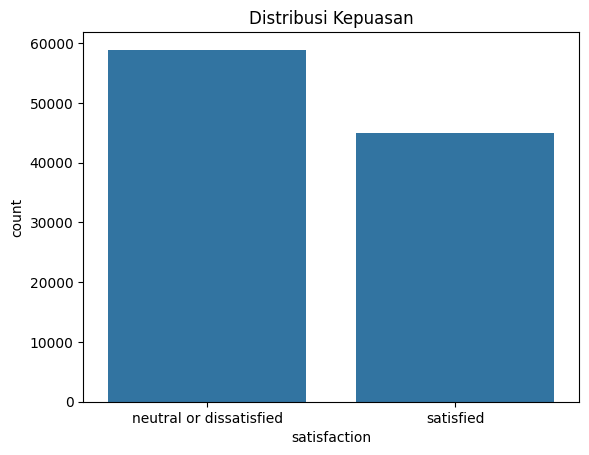

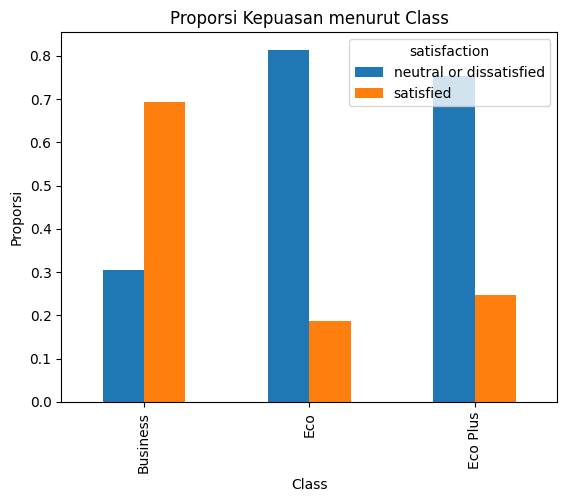

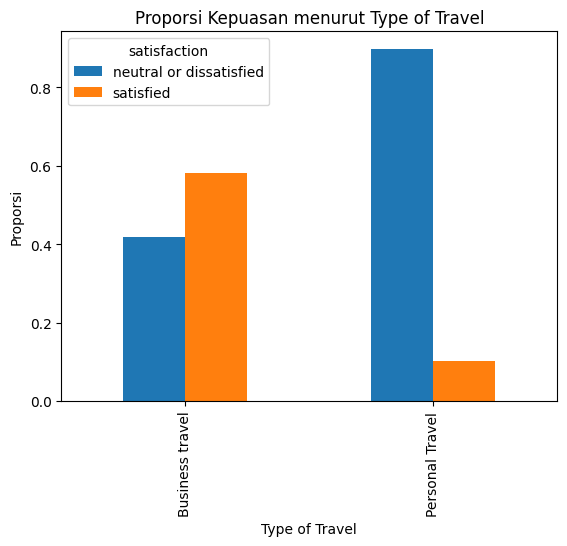

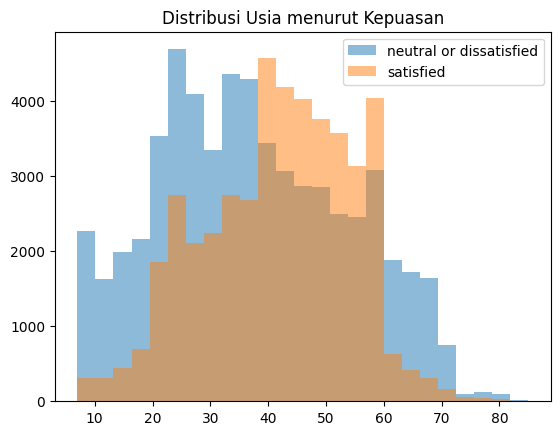

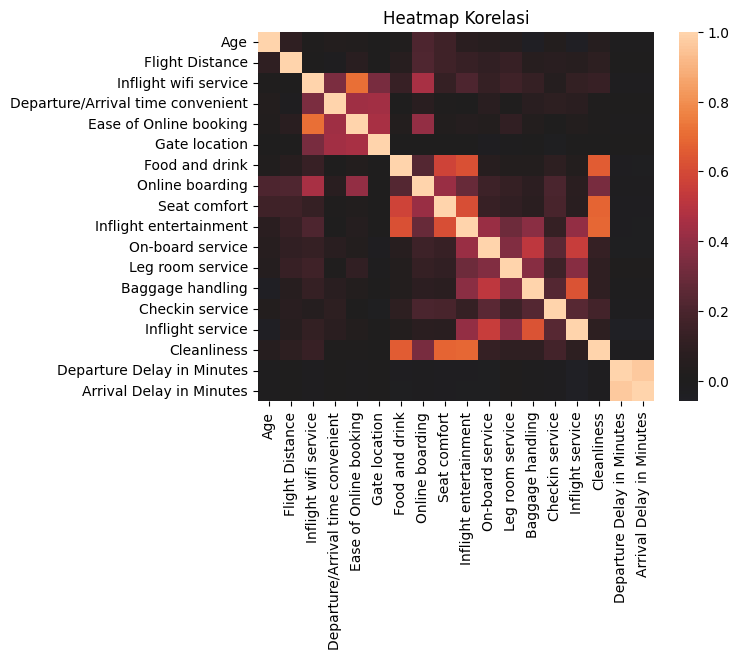

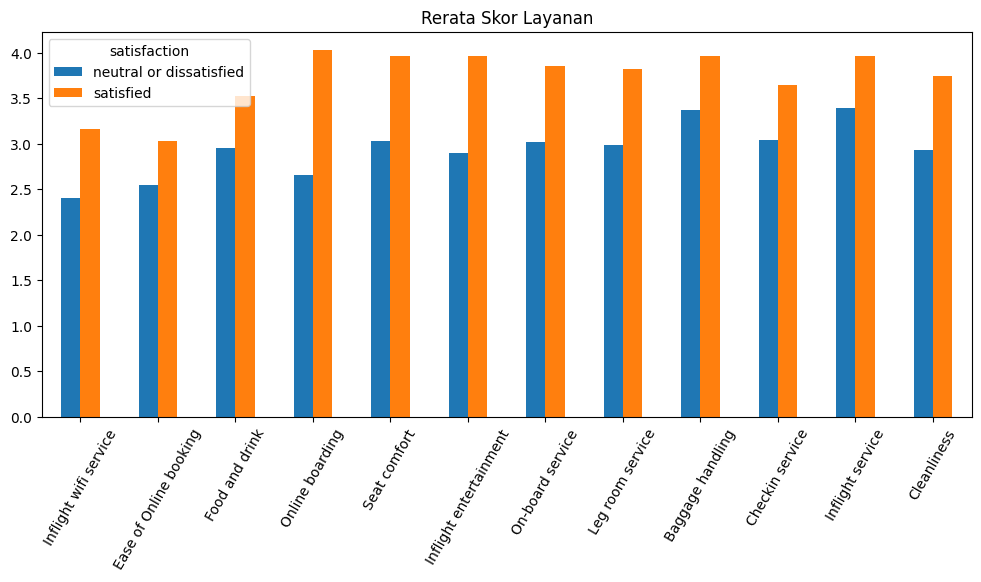

In [9]:
import seaborn as sns
sns.countplot(data=train_df,x="satisfaction")
plt.title("Distribusi Kepuasan"); plt.show()
pd.crosstab(train_df["Class"],train_df["satisfaction"],normalize="index").plot(kind="bar")
plt.title("Proporsi Kepuasan menurut Class"); plt.ylabel("Proporsi"); plt.show()
pd.crosstab(train_df["Type of Travel"],train_df["satisfaction"],normalize="index").plot(kind="bar")
plt.title("Proporsi Kepuasan menurut Type of Travel"); plt.ylabel("Proporsi"); plt.show()
for lab,sub in train_df.groupby("satisfaction"):
    plt.hist(sub["Age"].dropna(),bins=25,alpha=.5,label=lab)
plt.title("Distribusi Usia menurut Kepuasan"); plt.legend(); plt.show()
corr_cols=[c for c in ["Age","Flight Distance","Inflight wifi service","Departure/Arrival time convenient","Ease of Online booking","Gate location","Food and drink","Online boarding","Seat comfort","Inflight entertainment","On-board service","Leg room service","Baggage handling","Checkin service","Inflight service","Cleanliness","Departure Delay in Minutes","Arrival Delay in Minutes"] if c in train_df.columns]
sns.heatmap(train_df[corr_cols].corr(),center=0); plt.title("Heatmap Korelasi"); plt.show()
service_cols=[c for c in ["Inflight wifi service","Ease of Online booking","Food and drink","Online boarding","Seat comfort","Inflight entertainment","On-board service","Leg room service","Baggage handling","Checkin service","Inflight service","Cleanliness"] if c in train_df.columns]
train_df.groupby("satisfaction")[service_cols].mean().T.plot(kind="bar",figsize=(12,5))
plt.title("Rerata Skor Layanan"); plt.xticks(rotation=60); plt.show()

## 5. Pipeline dan model

In [10]:
def build_lr():
    pre=ColumnTransformer([
      ("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),num_cols),
      ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),cat_cols)])
    return Pipeline([("preprocessor",pre),("model",LogisticRegression(max_iter=1000,random_state=42))])
def build_rf():
    pre=ColumnTransformer([
      ("num",Pipeline([("imputer",SimpleImputer(strategy="median"))]),num_cols),
      ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),cat_cols)])
    return Pipeline([("preprocessor",pre),("model",RandomForestClassifier(n_estimators=80,min_samples_leaf=2,n_jobs=-1,random_state=42))])
results=[]
for name,model in [("Logistic Regression",build_lr()),("Random Forest",build_rf())]:
    t=time.time(); model.fit(X_tr,y_tr); elapsed=time.time()-t
    pred=model.predict(X_val); prob=model.predict_proba(X_val)[:,1]
    results.append({"Nama":name,"model":model,"Accuracy":accuracy_score(y_val,pred),
        "Macro-F1":f1_score(y_val,pred,average="macro"),
        "Balanced Accuracy":balanced_accuracy_score(y_val,pred),"ROC-AUC":roc_auc_score(y_val,prob),
        "Waktu latih (detik)":elapsed})
display(pd.DataFrame([{k:v for k,v in r.items() if k!="model"} for r in results]))

,Nama,Accuracy,Macro-F1,Balanced Accuracy,ROC-AUC,Waktu latih (detik)
0,Logistic Regression,0.876522,0.873794,0.872431,0.928093,0.773527
1,Random Forest,0.962129,0.961326,0.959987,0.994200,9.735364


## 6. Pemilihan model dan evaluasi test

Model terpilih: Random Forest
Accuracy: 0.9628888204496459
Macro-F1: 0.9622018174224445
Balanced accuracy: 0.9607444566020423
ROC-AUC: 0.9939981436179088
                         precision    recall  f1-score   support

neutral or dissatisfied       0.96      0.98      0.97     14573
              satisfied       0.97      0.94      0.96     11403

               accuracy                           0.96     25976
              macro avg       0.96      0.96      0.96     25976
           weighted avg       0.96      0.96      0.96     25976



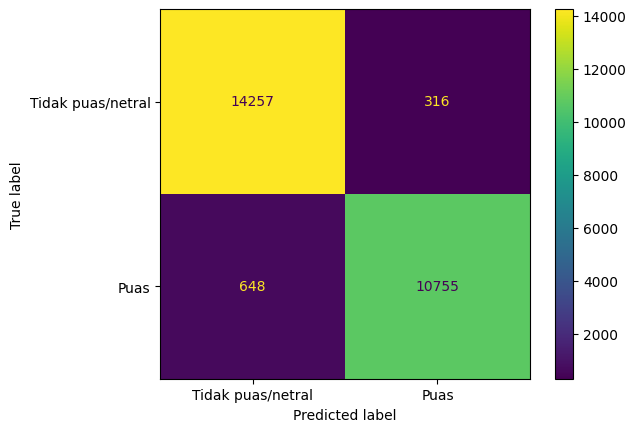

In [11]:
best=max(results,key=lambda r:r["Macro-F1"])
best_model=best["model"]
print("Model terpilih:",best["Nama"])
best_model.fit(X,y)
pred=best_model.predict(X_test); prob=best_model.predict_proba(X_test)[:,1]
print("Accuracy:",accuracy_score(y_test,pred))
print("Macro-F1:",f1_score(y_test,pred,average="macro"))
print("Balanced accuracy:",balanced_accuracy_score(y_test,pred))
print("ROC-AUC:",roc_auc_score(y_test,prob))
print(classification_report(y_test,pred,target_names=["neutral or dissatisfied","satisfied"]))
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=["Tidak puas/netral","Puas"],values_format="d")
plt.show()

## 7. Permutation importance

,Fitur,Penurunan Macro-F1
3,Type of Travel,0.174508
6,Inflight wifi service,0.130992
1,Customer Type,0.075492
11,Online boarding,0.030790
17,Checkin service,0.029178
16,Baggage handling,0.027490
4,Class,0.022176
12,Seat comfort,0.021239
18,Inflight service,0.020328
19,Cleanliness,0.016417


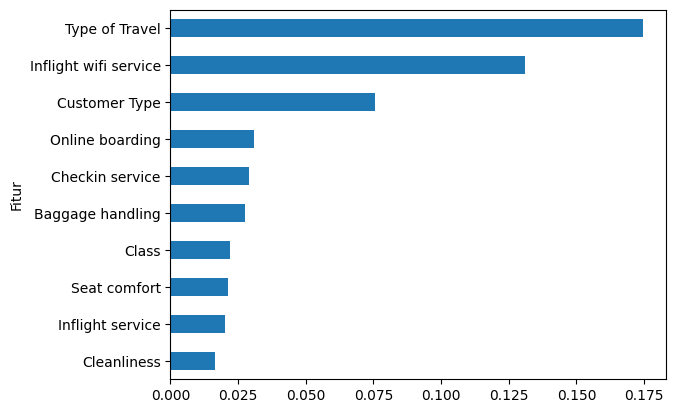

In [12]:
importance_model=build_lr() if best["Nama"]=="Logistic Regression" else build_rf()
importance_model.fit(X_tr,y_tr)
perm=permutation_importance(importance_model,X_val,y_val,scoring="f1_macro",n_repeats=2,random_state=42,n_jobs=-1)
imp=pd.DataFrame({"Fitur":X.columns,"Penurunan Macro-F1":perm.importances_mean}).sort_values("Penurunan Macro-F1",ascending=False)
display(imp.head(10))
imp.head(10).sort_values("Penurunan Macro-F1").plot(x="Fitur",y="Penurunan Macro-F1",kind="barh",legend=False)
plt.show()

## 8. Interpretasi dan keterbatasan
- Identifier seperti `id` dan `Unnamed: 0` dikeluarkan karena bukan karakteristik layanan yang bermakna.
- Median digunakan untuk nilai numerik kosong dan modus untuk kategori; imputasi dipasang dalam pipeline agar tidak terjadi data leakage.
- Macro-F1 menilai keseimbangan kinerja pada kedua kelas, sehingga accuracy saja belum cukup.
- Selisih performa train dan validation yang besar dapat menjadi indikasi overfitting.
- Korelasi dan permutation importance tidak membuktikan hubungan sebab-akibat.
- Test set digunakan untuk evaluasi final, bukan untuk tuning berulang.